# Generating correlated returns

A correlated random vector is formed by shifting and linearly combining independent standard-normal shocks:

$$
X=\mu+LZ,\qquad Z\sim\mathcal N(0,I_p),\qquad
\operatorname{Cov}(X)=LL^{\mathsf T}=\Sigma.
$$

Here, $X$ is the simulated $p$-dimensional vector; $\mu$ is its mean; $L$ is a square-root matrix of the covariance. $Z$ is a $p$-dimensional standard-normal vector; $I_p$ is the $p\times p$ identity matrix; $\Sigma$ is the covariance matrix.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]

from RiskLabAI.data.synthetic_data import form_block_matrix, form_true_matrix, random_cov, simulates_cov_mu

FIGURES = ROOT / "outputs" / "figures" / "02_synthetic_financial_environments"
TABLES = ROOT / "outputs" / "tables" / "02_synthetic_financial_environments"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {
    "background": "#FFFFFF",
    "axes": "#FFFFFF",
    "text": "#1B365D",
    "cyan": "#0072B2",
    "amber": "#C76D00",
    "green": "#00866A",
    "rose": "#B83B3B",
    "violet": "#A03A78",
    "grid": "#D9DEE5",
}
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11.5,
    "figure.facecolor": palette["background"],
    "axes.facecolor": palette["axes"],
    "axes.edgecolor": palette["text"],
    "axes.labelcolor": palette["text"],
    "axes.titlecolor": palette["text"],
    "xtick.color": palette["text"],
    "ytick.color": palette["text"],
    "text.color": palette["text"],
    "grid.color": palette["grid"],
    "grid.linestyle": ":",
    "legend.facecolor": palette["axes"],
    "legend.edgecolor": palette["grid"],
    "savefig.facecolor": palette["background"],
})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Equicorrelation Blocks

The matrix has unit variances and one common correlation, with one large eigenvalue and $m-1$ equal smaller ones:

$$
B_m(\rho)=(1-\rho)I_m+\rho\mathbf 1_m\mathbf 1_m^{\mathsf T},\qquad
\lambda(B_m)=\{1+(m-1)\rho,\underbrace{1-\rho,\ldots,1-\rho}_{m-1}\}.
$$

Here, $B_m(\rho)$ is an $m\times m$ equicorrelation matrix; $\rho$ is the common off-diagonal correlation. $I_m$ is the identity matrix; $\mathbf 1_m$ is a vector of $m$ ones; $\lambda(B_m)$ is the set of eigenvalues; $m$ is block size.

In [2]:
block_count = 4
block_size = 5
within_block_correlation = 0.65
dimension = block_count * block_size
block_correlation = form_block_matrix(block_count, block_size, within_block_correlation)
block_eigenvalues = np.linalg.eigvalsh(block_correlation)

np.random.seed(20260926)
true_mean, true_covariance = form_true_matrix(block_count, block_size, within_block_correlation)
true_standard_deviation = np.sqrt(np.diag(true_covariance))
true_correlation = true_covariance / np.outer(true_standard_deviation, true_standard_deviation)

np.random.seed(20260927)
factor_covariance = random_cov(num_columns=dimension, num_factors=3)

covariance_design = pd.DataFrame({
    "Design quantity": [
        "Dimension",
        "Number of blocks",
        "Assets per block",
        "Within-block correlation",
        "Smallest block eigenvalue",
        "Largest block eigenvalue",
        "Factor covariance rank contribution",
        "Smallest factor covariance eigenvalue",
    ],
    "Value": [
        dimension,
        block_count,
        block_size,
        within_block_correlation,
        block_eigenvalues.min(),
        block_eigenvalues.max(),
        3,
        np.linalg.eigvalsh(factor_covariance).min(),
    ],
})
save_table(covariance_design, "covariance_design", "Design quantities for the structured and factor covariance generators.", "tab:covariance-design", fit=False)
display(covariance_design.round(6))

,Design quantity,Value
0,Dimension,20
1,Number of blocks,4
2,Assets per block,5
3,Within-block correlation,0.650000
4,Smallest block eigenvalue,0.350000
5,Largest block eigenvalue,3.600000
6,Factor covariance rank contribution,3
7,Smallest factor covariance eigenvalue,0.036205


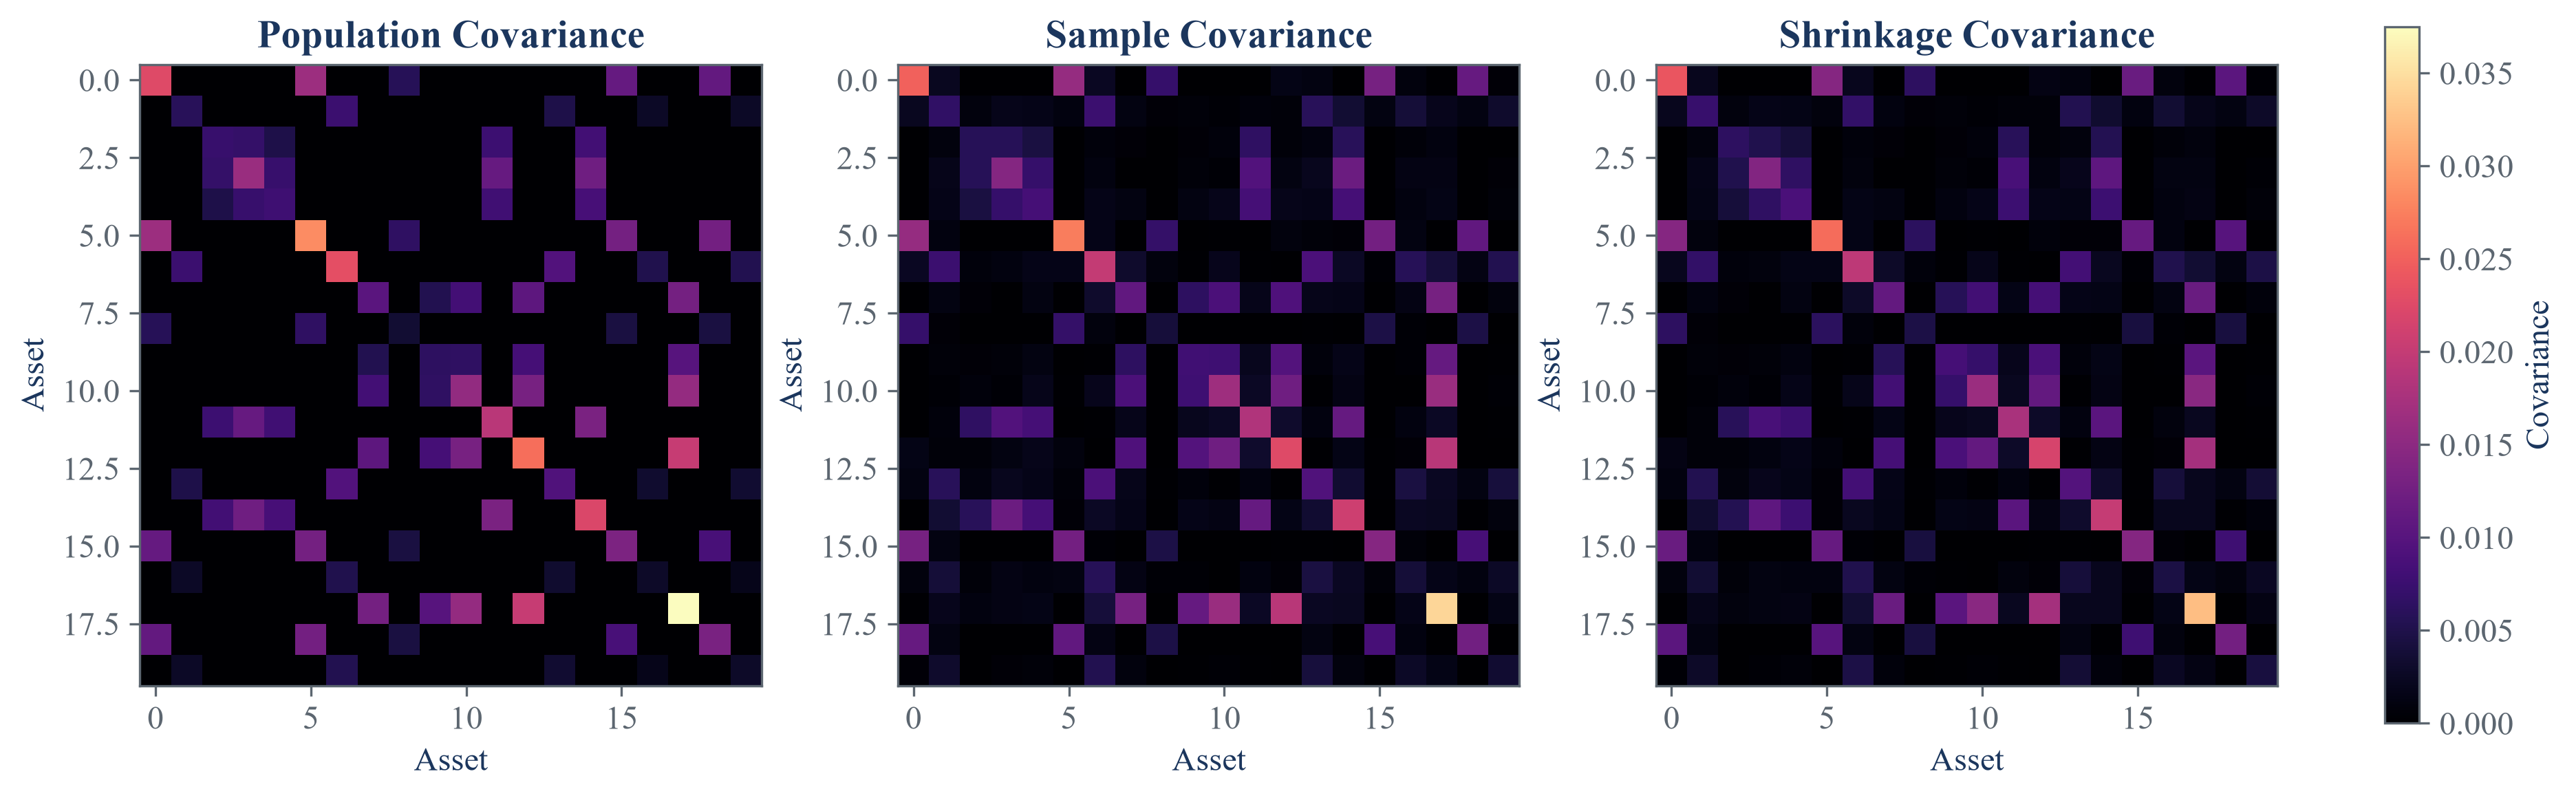

In [3]:
np.random.seed(20260928)
sample_mean, sample_covariance = simulates_cov_mu(true_mean, true_covariance, n_obs=120, shrink=False)
np.random.seed(20260928)
shrinkage_mean, shrinkage_covariance = simulates_cov_mu(true_mean, true_covariance, n_obs=120, shrink=True)

covariance_limit = max(true_covariance.max(), sample_covariance.max(), shrinkage_covariance.max())
figure, axes = plt.subplots(1, 3, figsize=(12.4, 4.3), constrained_layout=True)
images = []
for axis, matrix, title in zip(
    axes,
    [true_covariance, sample_covariance, shrinkage_covariance],
    ["Population Covariance", "Sample Covariance", "Shrinkage Covariance"],
):
    image = axis.imshow(matrix, cmap="magma", vmin=0.0, vmax=covariance_limit)
    images.append(image)
    axis.set_xlabel("Asset")
    axis.set_ylabel("Asset")
    axis.set_title(title)
figure.colorbar(images[-1], ax=axes, shrink=0.80, label="Covariance")
figure.savefig(FIGURES / "covariance_structures.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "covariance_structures.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "covariance_structures.png")))
plt.close(figure)

## Finite-Sample Estimation

The first expression estimates covariance, the second blends it with a target, and the third measures relative error:

$$
S_n=\frac{1}{n-1}\sum_{i=1}^{n}(X_i-\overline X)(X_i-\overline X)^{\mathsf T},\qquad
\widehat\Sigma_{\delta}=\delta F+(1-\delta)S_n,
\qquad
\mathcal L(\widehat\Sigma)=\frac{\lVert\widehat\Sigma-\Sigma\rVert_F}{\lVert\Sigma\rVert_F}.
$$

Here, $X_i$ is observation $i$; $\overline X$ is the sample mean; $n$ is sample size; $S_n$ is sample covariance. $F$ is the shrinkage target; $\delta\in[0,1]$ is the target weight; $\widehat\Sigma_\delta$ is the blended estimate; $\Sigma$ is true covariance. $\mathcal L$ is relative covariance error; $\lVert\cdot\rVert_F$ is the Frobenius norm.

In [4]:
sample_sizes = np.array([40, 80, 160, 320, 640])
repetitions = 100
records = []

for sample_size_index, sample_size in enumerate(sample_sizes):
    for repetition in range(repetitions):
        seed = 20261000 + sample_size_index * repetitions + repetition
        np.random.seed(seed)
        estimated_mean, estimated_covariance = simulates_cov_mu(true_mean, true_covariance, n_obs=int(sample_size), shrink=False)
        np.random.seed(seed)
        repeated_mean, shrunk_covariance = simulates_cov_mu(true_mean, true_covariance, n_obs=int(sample_size), shrink=True)
        records.append({
            "Sample size": int(sample_size),
            "Sample covariance error": np.linalg.norm(estimated_covariance - true_covariance, ord="fro") / np.linalg.norm(true_covariance, ord="fro"),
            "Shrinkage covariance error": np.linalg.norm(shrunk_covariance - true_covariance, ord="fro") / np.linalg.norm(true_covariance, ord="fro"),
            "Mean error": np.linalg.norm(estimated_mean - true_mean),
            "Paired means agree": np.array_equal(estimated_mean, repeated_mean),
        })

covariance_trials = pd.DataFrame(records)
covariance_estimation_summary = covariance_trials.groupby("Sample size").agg(
    Median_sample_error=("Sample covariance error", "median"),
    Median_shrinkage_error=("Shrinkage covariance error", "median"),
    Median_mean_error=("Mean error", "median"),
).reset_index()
shrinkage_frequency = covariance_trials.assign(
    Better=covariance_trials["Shrinkage covariance error"] < covariance_trials["Sample covariance error"]
).groupby("Sample size")["Better"].mean().to_numpy()
covariance_estimation_summary["Shrinkage improvement frequency"] = shrinkage_frequency
covariance_estimation_summary.columns = [
    "Sample size",
    "Median sample covariance error",
    "Median shrinkage covariance error",
    "Median mean error",
    "Shrinkage improvement frequency",
]
save_table(covariance_estimation_summary, "covariance_estimation_summary", "Monte Carlo covariance and mean estimation errors by sample size.", "tab:covariance-estimation-summary")
display(covariance_estimation_summary.round(6))

,Sample size,Median sample covariance error,Median shrinkage covariance error,Median mean error,Shrinkage improvement frequency
0,40,0.420950,0.389442,0.083041,0.77
1,80,0.308723,0.286867,0.058812,0.76
2,160,0.210292,0.205407,0.040666,0.56
3,320,0.152329,0.148245,0.027794,0.57
4,640,0.105801,0.104448,0.020136,0.58


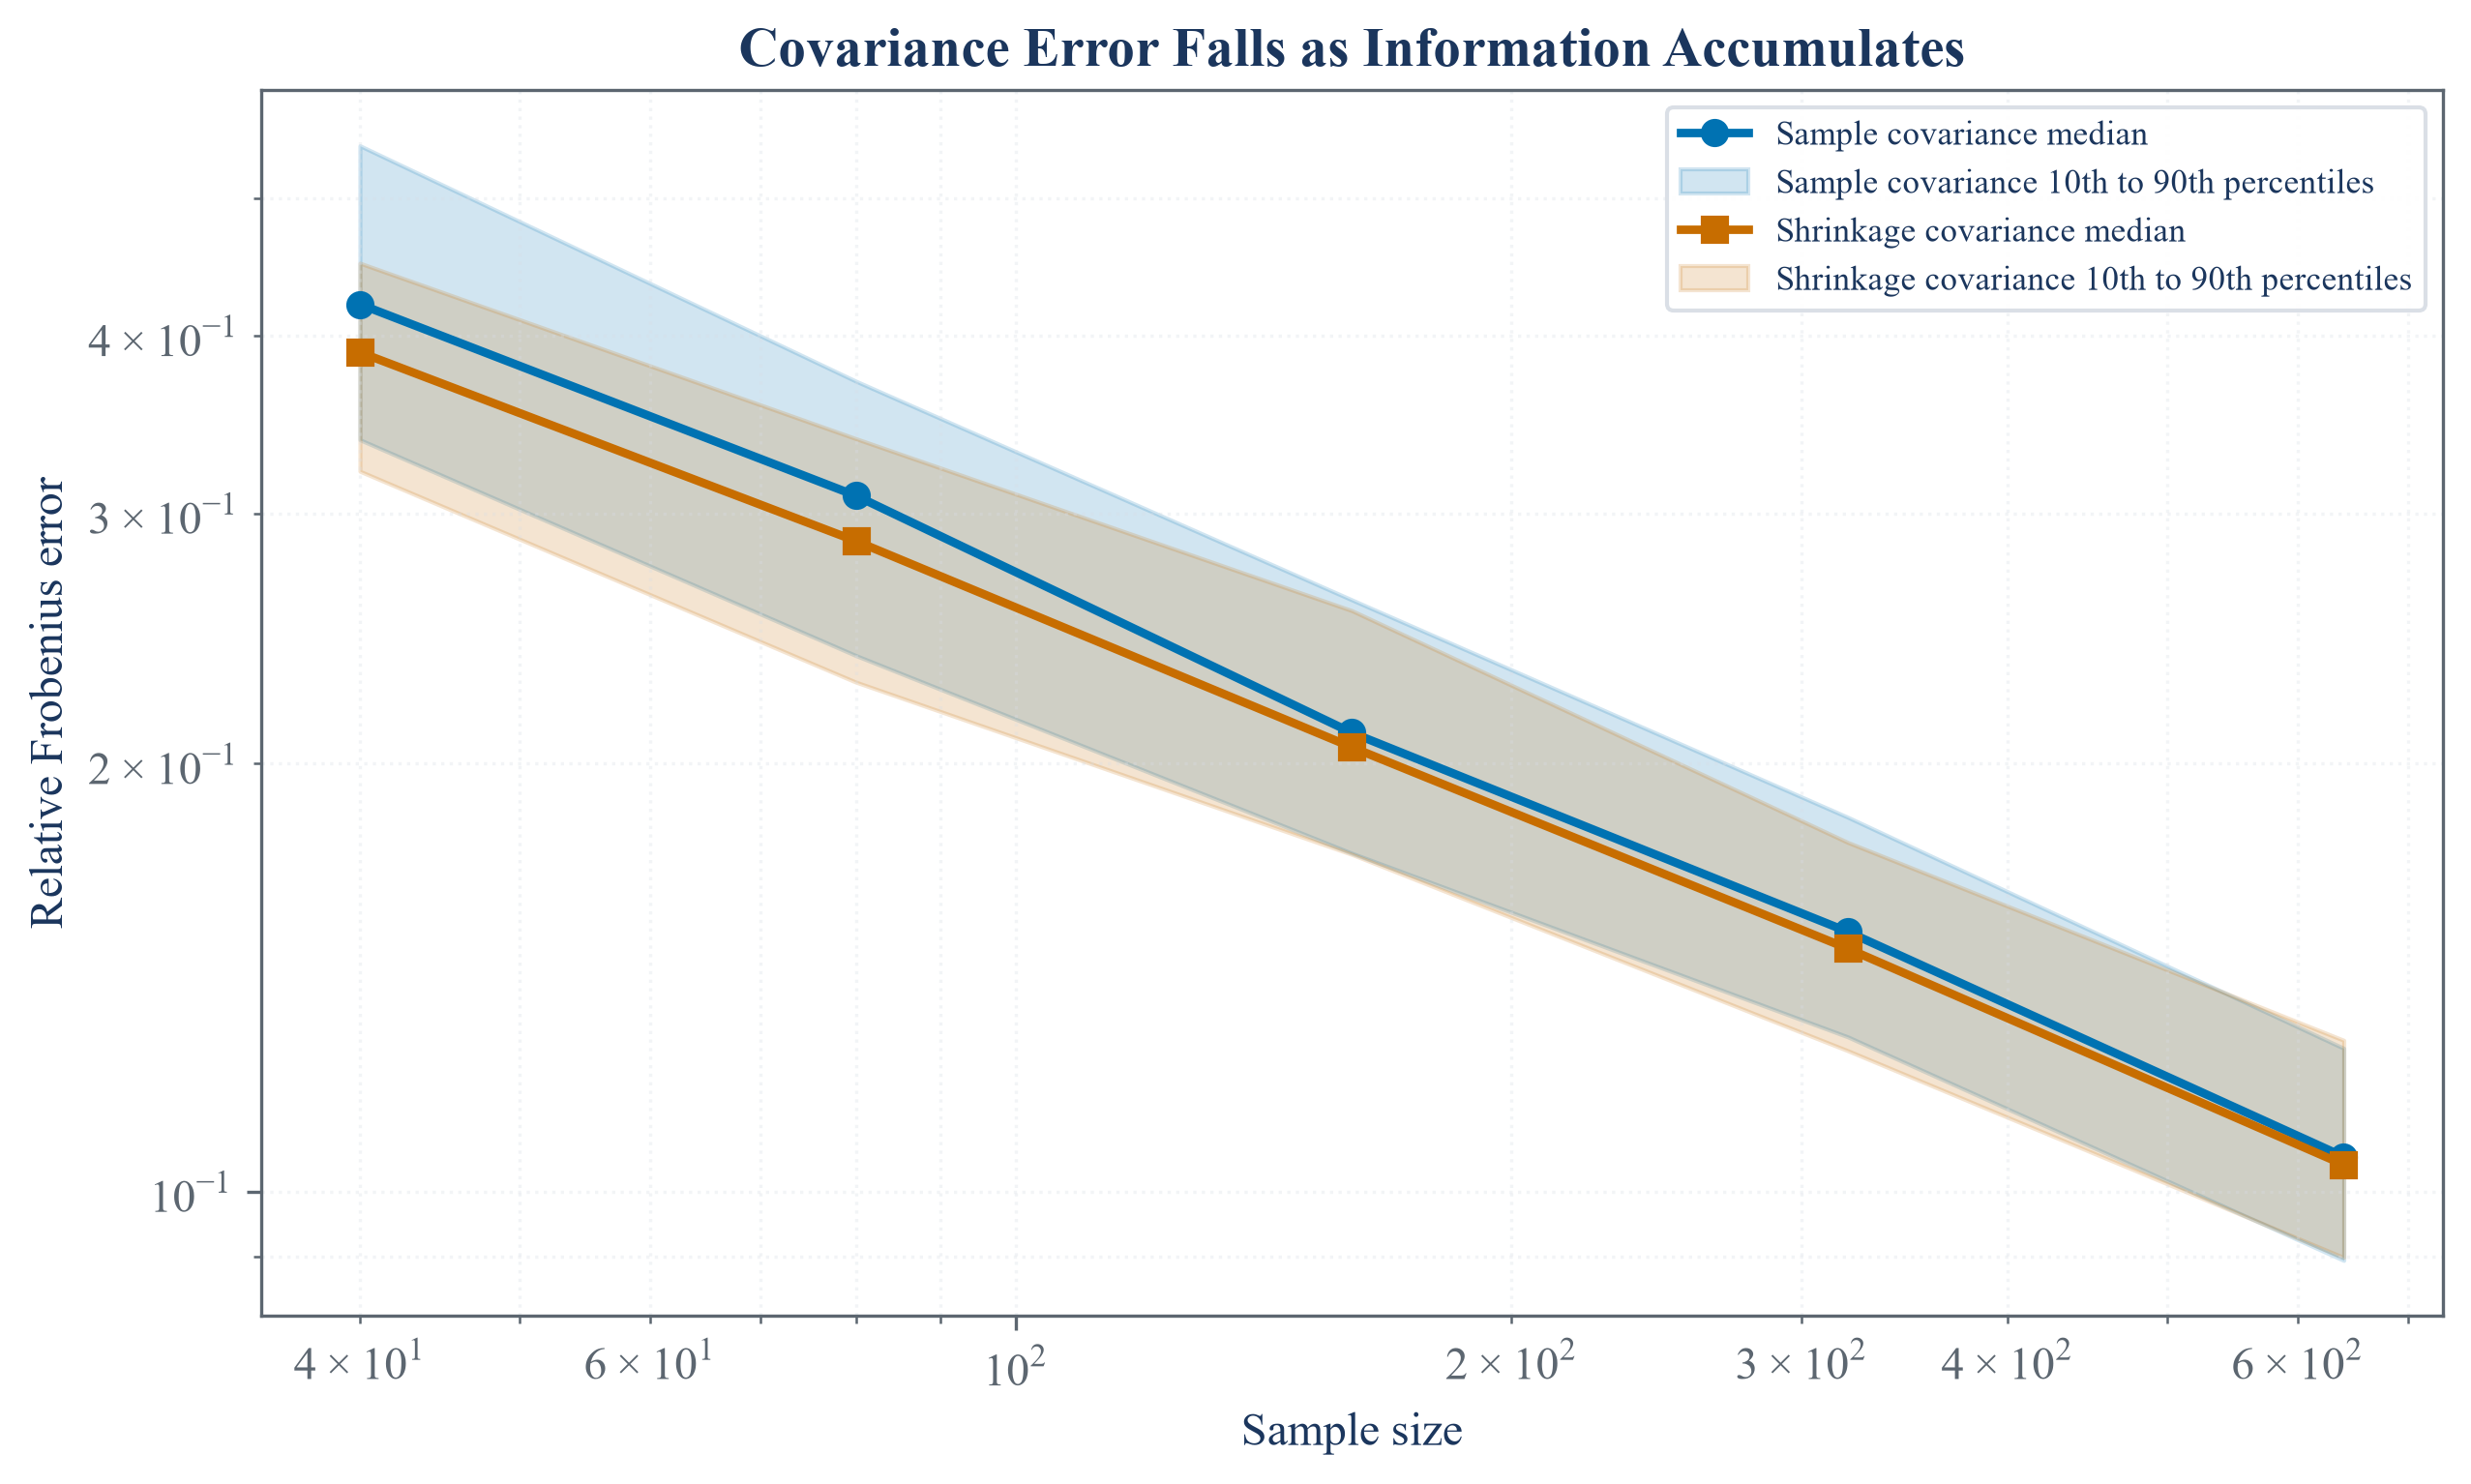

In [5]:
sample_quantiles = covariance_trials.groupby("Sample size")["Sample covariance error"].quantile([0.10, 0.50, 0.90]).unstack()
shrinkage_quantiles = covariance_trials.groupby("Sample size")["Shrinkage covariance error"].quantile([0.10, 0.50, 0.90]).unstack()

figure, axis = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
axis.loglog(sample_sizes, sample_quantiles[0.50], marker="o", color=palette["cyan"], linewidth=2.1, label="Sample covariance median")
axis.fill_between(sample_sizes, sample_quantiles[0.10], sample_quantiles[0.90], color=palette["cyan"], alpha=0.18, label="Sample covariance 10th to 90th percentiles")
axis.loglog(sample_sizes, shrinkage_quantiles[0.50], marker="s", color=palette["amber"], linewidth=2.1, label="Shrinkage covariance median")
axis.fill_between(sample_sizes, shrinkage_quantiles[0.10], shrinkage_quantiles[0.90], color=palette["amber"], alpha=0.18, label="Shrinkage covariance 10th to 90th percentiles")
axis.set_xlabel("Sample size")
axis.set_ylabel("Relative Frobenius error")
axis.set_title("Covariance Error Falls as Information Accumulates")
axis.grid(True, which="both", alpha=0.32)
axis.legend(fontsize=8.4)
figure.savefig(FIGURES / "covariance_error_convergence.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "covariance_error_convergence.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "covariance_error_convergence.png")))
plt.close(figure)

## Tests

In [6]:
theoretical_eigenvalues = np.sort(np.concatenate(([1.0 + (block_size - 1) * within_block_correlation], np.repeat(1.0 - within_block_correlation, block_size - 1))))
assert block_correlation.shape == (dimension, dimension)
assert np.allclose(block_correlation, block_correlation.T)
assert np.allclose(np.linalg.eigvalsh(block_correlation[:block_size, :block_size]), theoretical_eigenvalues)
assert np.linalg.eigvalsh(block_correlation).min() > 0.0
assert true_mean.shape == (dimension, 1)
assert true_covariance.shape == (dimension, dimension)
assert np.allclose(np.diag(true_correlation), 1.0)
assert np.linalg.eigvalsh(true_covariance).min() > 0.0
assert np.linalg.eigvalsh(factor_covariance).min() > 0.0
assert np.array_equal(sample_mean, shrinkage_mean)
assert sample_covariance.shape == shrinkage_covariance.shape == true_covariance.shape
assert covariance_trials["Paired means agree"].all()
assert len(covariance_trials) == len(sample_sizes) * repetitions
assert covariance_estimation_summary["Median sample covariance error"].iloc[-1] < covariance_estimation_summary["Median sample covariance error"].iloc[0]
assert covariance_estimation_summary["Median shrinkage covariance error"].iloc[-1] < covariance_estimation_summary["Median shrinkage covariance error"].iloc[0]
assert covariance_estimation_summary["Median shrinkage covariance error"].iloc[0] < covariance_estimation_summary["Median sample covariance error"].iloc[0]
assert covariance_estimation_summary["Shrinkage improvement frequency"].between(0.0, 1.0).all()